# 07 – Phân loại Cảnh báo Ô nhiễm, Tối ưu Ngưỡng & Kiểm toán Rò rỉ Dữ liệu (Issue #13, W11)

**Môn học:** INFO3020 – Nhập môn Khoa học Dữ liệu (*Introduction to Data Science*) – ĐH CMC<br>
**Dữ liệu nguồn:** `data/processed/air_pollution_final.parquet` (Trạm NCEM/VEA 556 Nguyễn Văn Cừ, Hà Nội)<br>
**Quy chuẩn áp dụng:** QCVN 05:2023/BTNMT — Giá trị giới hạn nồng độ bụi mịn PM₂.₅ trung bình 24 giờ là 50 µg/m³<br>
**Mục tiêu nghiên cứu:** Xây dựng hệ thống phân loại nhị phân cảnh báo sớm các đợt ô nhiễm vượt ngưỡng an toàn dựa trên đặc trưng quá khứ, giải quyết bài toán mất cân bằng lớp qua đường cong Precision-Recall (PR-AUC), tối ưu hóa ngưỡng quyết định theo mục tiêu bảo vệ sức khỏe cộng đồng ($F_2$ score), và thực hiện kiểm toán rà soát 4 dạng rò rỉ dữ liệu.

---

## Các Câu Hỏi Nghiên Cứu Cốt Lõi (RQ4)

1. **Định nghĩa Nhãn tương thích Quy chuẩn:** Làm thế nào để định nghĩa nhãn cảnh báo ô nhiễm nhị phân bảo đảm tính tương thích toán học về chu kỳ lấy mẫu 24h của QCVN 05:2023/BTNMT mà không vi phạm rò rỉ dữ liệu tương lai?
2. **Kỹ nghệ Đặc trưng Quá khứ:** Liệu các biến thống kê trượt quá khứ (trung bình, độ lệch chuẩn 24h) kết hợp với các tham số thời tiết bề mặt có đủ sức mạnh phân biệt các đợt bùng phát ô nhiễm?
3. **Bẫy Accuracy & Đánh giá qua PR-AUC:** Khi tỷ lệ vượt ngưỡng trong dữ liệu bị mất cân bằng, tại sao Accuracy trở thành cái bẫy nguy hiểm và đường cong Precision-Recall phản ánh hiệu năng trung thực như thế nào?
4. **Tối ưu Ngưỡng Quyết định:** Làm thế nào để giải quyết sự đánh đổi giữa Precision (báo động giả) và Recall (bỏ sót cảnh báo nguy hại) thông qua việc tinh chỉnh ngưỡng trên tập Train/Validation theo hàm mục tiêu $F_\beta$ ($\beta > 1$)?
5. **Kiểm toán Rò rỉ Dữ liệu:** Đảm bảo hệ thống đạt chuẩn qua 4 tiêu chí kiểm toán: Target, Train-Test contamination, Temporal, và Group leakage.


In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

warnings.filterwarnings("ignore")

# Cố định hạt giống ngẫu nhiên theo quy định toàn dự án
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Thiết lập đường dẫn thư mục gốc repo
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.classification import (
    DEFAULT_SPLIT_TIMESTAMP,
    ClassificationResults,
    compute_feature_importances,
    engineer_classification_features,
    evaluate_classifier,
    generate_leakage_audit_markdown,
    prepare_classification_data,
    render_feature_importance_figure,
    render_pr_curve_figure,
    run_classification_pipeline,
    tune_classification_threshold,
    write_classification_findings,
    write_classification_report,
)
from src.cleaning_pipeline import (
    DEFAULT_ALERT_MIN_PERIODS,
    DEFAULT_ALERT_THRESHOLD_UG_M3,
    DEFAULT_ALERT_WINDOW_HOURS,
    build_alert_label,
)

DATA_PATH = REPO_ROOT / "data" / "processed" / "air_pollution_final.parquet"
PR_FIG_PATH = REPO_ROOT / "figures" / "precision_recall_curve.png"
FEAT_FIG_PATH = REPO_ROOT / "figures" / "feature_importance.png"
AUDIT_REPORT_PATH = REPO_ROOT / "reports" / "classification_leakage_audit.md"
RESULTS_REPORT_PATH = REPO_ROOT / "reports" / "classification_results.md"
FINDINGS_DOC_PATH = REPO_ROOT / "docs" / "classification_findings.md"

print(f"Data path: {DATA_PATH.resolve()}")
print(f"Tồn tại trên đĩa: {DATA_PATH.exists()}")


Data path: C:\Users\Huy Nguyen\orca\workspaces\air-pollution-analysis\M4-progress\data\processed\air_pollution_final.parquet
Tồn tại trên đĩa: True


## 1. Định nghĩa Nhãn Cảnh báo & Đo lường Mất cân bằng Lớp (Task 0.7b)

QCVN 05:2023/BTNMT quy định giới hạn trung bình 24 giờ là 50 µg/m³. Nhãn nhị phân $y_t$ được xác định:
$$ y_t = \mathbb{I}\left(\frac{1}{24}\sum_{i=0}^{23} \text{PM}_{2.5, t-i} \ge 50.0\right) $$
- **Xử lý thiếu dữ liệu:** Yêu cầu đủ `min_periods = 24` giờ liên tục không có NaN. Nếu thiếu dữ liệu, nhãn là `NaN` (không suy diễn võ đoán).
- **Thống nhất hai mẫu số:**
  1. *Mẫu số hợp lệ (Valid rolling):* 5.317 giờ $\to$ Tỷ lệ dương: 31,13% (1.655 / 5.317).
  2. *Mẫu số toàn bộ thời gian:* 9.044 giờ $\to$ Tỷ lệ dương: 18,30% (1.655 / 9.044).


In [2]:
df = pd.read_parquet(DATA_PATH)
X_train, y_train, X_test, y_test, metadata = prepare_classification_data(
    df, split_timestamp=DEFAULT_SPLIT_TIMESTAMP
)

print("THỐNG KÊ MẪU SỐ VÀ TỶ LỆ DƯƠNG (PREVALENCE):")
print(f"  Train: {metadata['n_train_valid']:,} dòng hợp lệ / {metadata['n_train_total']:,} tổng dòng")
print(f"         Prevalence (mẫu số hợp lệ): {metadata['train_prevalence_valid']:.2%}")
print(f"         Prevalence (toàn bộ thời gian): {metadata['train_prevalence_all']:.2%}")
print(f"  Test:  {metadata['n_test_valid']:,} dòng hợp lệ / {metadata['n_test_total']:,} tổng dòng")
print(f"         Prevalence (mẫu số hợp lệ): {metadata['test_prevalence_valid']:.2%}")
print(f"         Prevalence (toàn bộ thời gian): {metadata['test_prevalence_all']:.2%}")


THỐNG KÊ MẪU SỐ VÀ TỶ LỆ DƯƠNG (PREVALENCE):
  Train: 2,965 dòng hợp lệ / 4,682 tổng dòng
         Prevalence (mẫu số hợp lệ): 32.98%
         Prevalence (toàn bộ thời gian): 20.89%
  Test:  2,302 dòng hợp lệ / 4,362 tổng dòng
         Prevalence (mẫu số hợp lệ): 28.93%
         Prevalence (toàn bộ thời gian): 15.27%


## 2. Kỹ nghệ Đặc trưng Quá khứ (Past-only Feature Engineering)

Quy tắc bất biến: **Tuyệt đối không truy xuất thông tin tương lai**.
- Thống kê trượt quá khứ `pm25_rolling_mean_24h` và `pm25_rolling_std_24h` được tính với `shift(1)`, chỉ sử dụng dữ liệu từ $t-1$ trở về trước.
- Biến trễ `pm25_lag24`: nồng độ đúng 24 giờ trước.
- Biến khí tượng bề mặt và cờ lặng gió (`wind_speed < 0.5 m/s`).
- Tái sử dụng 4 cột chu kỳ có sẵn trong Parquet: `hour_sin`, `hour_cos`, `month_sin`, `month_cos`.
- Loại bỏ hoàn toàn `pm10` (tránh đa cộng tuyến) và `pm25_was_missing` (tránh target leakage).


In [3]:
print(f"Số lượng đặc trưng đầu vào: {X_train.shape[1]}")
print("Danh sách đặc trưng:")
for col in X_train.columns:
    print(f"  - {col}")

display(X_train.head(3))


Số lượng đặc trưng đầu vào: 14
Danh sách đặc trưng:
  - pm25_rolling_mean_24h
  - pm25_rolling_std_24h
  - pm25_lag24
  - temperature
  - relative_humidity
  - temp_humidity_interaction
  - wind_speed
  - is_calm_wind
  - precipitation
  - surface_pressure
  - hour_sin
  - hour_cos
  - month_sin
  - month_cos


,pm25_rolling_mean_24h,pm25_rolling_std_24h,pm25_lag24,temperature,relative_humidity,temp_humidity_interaction,wind_speed,is_calm_wind,precipitation,surface_pressure,hour_sin,hour_cos,month_sin,month_cos
24,30.309729,7.939814,31.516667,26.9,89.0,2394.1,1.54,0.0,0.0,1003.4,-0.500000,0.866025,-0.5,-0.866025
25,30.831493,8.419536,33.672500,26.5,90.0,2385.0,1.16,0.0,0.0,1003.4,-0.258819,0.965926,-0.5,-0.866025
26,31.144495,8.665776,32.347000,26.2,91.0,2384.2,1.18,0.0,0.0,1002.9,0.000000,1.000000,-0.5,-0.866025


## 3. Huấn luyện Mô hình Phân loại

Huấn luyện 3 mô hình trên tập Train:
1. **Baseline DummyClassifier:** Chiến lược dự báo theo phân phối tiên nghiệm (`strategy='prior'`).
2. **Logistic Regression:** Áp dụng `class_weight='balanced'` để bù trừ mất cân bằng lớp và chuẩn hóa đặc trưng qua `RobustScaler`.
3. **Random Forest Classifier:** Rừng cây ngẫu nhiên 100 cây, độ sâu tối đa 8, trọng số lớp cân bằng.


In [4]:
# 1. Baseline
dummy = DummyClassifier(strategy="prior")
dummy.fit(X_train, y_train)

# 2. Logistic Regression
logreg = Pipeline([
    ("scaler", RobustScaler()),
    ("clf", LogisticRegression(class_weight="balanced", random_state=RANDOM_STATE, max_iter=1000)),
])
logreg.fit(X_train, y_train)

# 3. Random Forest
rf = RandomForestClassifier(
    n_estimators=100, max_depth=8, class_weight="balanced", random_state=RANDOM_STATE
)
rf.fit(X_train, y_train)

print("Đã hoàn thành huấn luyện 3 mô hình trên tập Train.")


Đã hoàn thành huấn luyện 3 mô hình trên tập Train.


## 4. Tinh chỉnh Ngưỡng Quyết định theo Mục tiêu Vận hành ($F_2$ Score)

Trong cảnh báo ô nhiễm không khí nguy hại, **bỏ sót một đợt ô nhiễm nặng (False Negative)** gây hậu quả sức khỏe nghiêm trọng hơn nhiều so với **báo động giả (False Positive)**.<br>
Do đó, hàm mục tiêu vận hành ưu tiên độ nhạy là $F_2$ score:
$$ F_2 = \frac{5 \cdot \text{Precision} \cdot \text{Recall}}{4 \cdot \text{Precision} + \text{Recall}} $$
Ngưỡng quyết định $\tau$ được tối ưu hoàn toàn trên tập Train qua 5-fold `TimeSeriesSplit` (tuyệt đối không tune trên tập Test).


In [5]:
tau_logreg = tune_classification_threshold(logreg, X_train, y_train, metric="f2")
tau_rf = tune_classification_threshold(rf, X_train, y_train, metric="f2")

# Đảm bảo các mô hình đã được huấn luyện trọn vẹn trên toàn bộ Train trước khi test
logreg.fit(X_train, y_train)
rf.fit(X_train, y_train)

print(f"Ngưỡng quyết định tối ưu F2 cho Logistic Regression: tau = {tau_logreg:.2f}")
print(f"Ngưỡng quyết định tối ưu F2 cho Random Forest:       tau = {tau_rf:.2f}")


Ngưỡng quyết định tối ưu F2 cho Logistic Regression: tau = 0.43
Ngưỡng quyết định tối ưu F2 cho Random Forest:       tau = 0.32


## 5. Đánh giá Độc lập trên Tập TEST & Vượt qua Bẫy Accuracy

Đánh giá hiệu năng của các mô hình trên tập Test độc lập với ngưỡng đã chốt.
- **Bẫy Accuracy:** Mô hình Baseline Dummy có thể đạt Accuracy $\approx 71\%$ (bằng tỷ lệ lớp đa số) nhưng Recall = 0.0% (hoàn toàn vô dụng trong việc cảnh báo ô nhiễm).
- **Tiêu chuẩn vàng:** Tập trung vào Recall, Precision, $F_2$, và PR-AUC.


In [6]:
m_dummy = evaluate_classifier("Baseline (Dummy Prior)", dummy, X_test, y_test, threshold=0.50)
m_logreg = evaluate_classifier("Logistic Regression (Balanced)", logreg, X_test, y_test, threshold=tau_logreg)
m_rf = evaluate_classifier("Random Forest (Balanced)", rf, X_test, y_test, threshold=tau_rf)

metrics_table = pd.DataFrame([{
    "Model": m.model_name,
    "Threshold": m.threshold,
    "Accuracy": f"{m.accuracy:.2%}",
    "Precision": f"{m.precision:.2%}",
    "Recall": f"{m.recall:.2%}",
    "F1": f"{m.f1:.4f}",
    "F2": f"{m.f2:.4f}",
    "ROC-AUC": f"{m.roc_auc:.4f}",
    "PR-AUC": f"{m.pr_auc:.4f}",
    "Confusion Matrix [TN, FP, FN, TP]": str(m.confusion_matrix),
} for m in [m_dummy, m_logreg, m_rf]])

print("BẢNG HIỆU NĂNG PHÂN LOẠI TRÊN TẬP TEST ĐỘC LẬP:")
display(metrics_table)


BẢNG HIỆU NĂNG PHÂN LOẠI TRÊN TẬP TEST ĐỘC LẬP:


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC,"Confusion Matrix [TN, FP, FN, TP]"
0,Baseline (Dummy Prior),0.50,71.07%,0.00%,0.00%,0.0000,0.0000,0.5000,0.2893,"[[1636, 0], [666, 0]]"
1,Logistic Regression (Balanced),0.43,98.09%,94.18%,99.55%,0.9679,0.9843,0.9995,0.9989,"[[1595, 41], [3, 663]]"
2,Random Forest (Balanced),0.32,98.83%,96.10%,100.00%,0.9801,0.9920,0.9995,0.9985,"[[1609, 27], [0, 666]]"


## 6. Đường cong Precision-Recall (PR Curve) vs Baseline Prevalence


Đã lưu biểu đồ PR Curve: C:\Users\Huy Nguyen\orca\workspaces\air-pollution-analysis\M4-progress\figures\precision_recall_curve.png


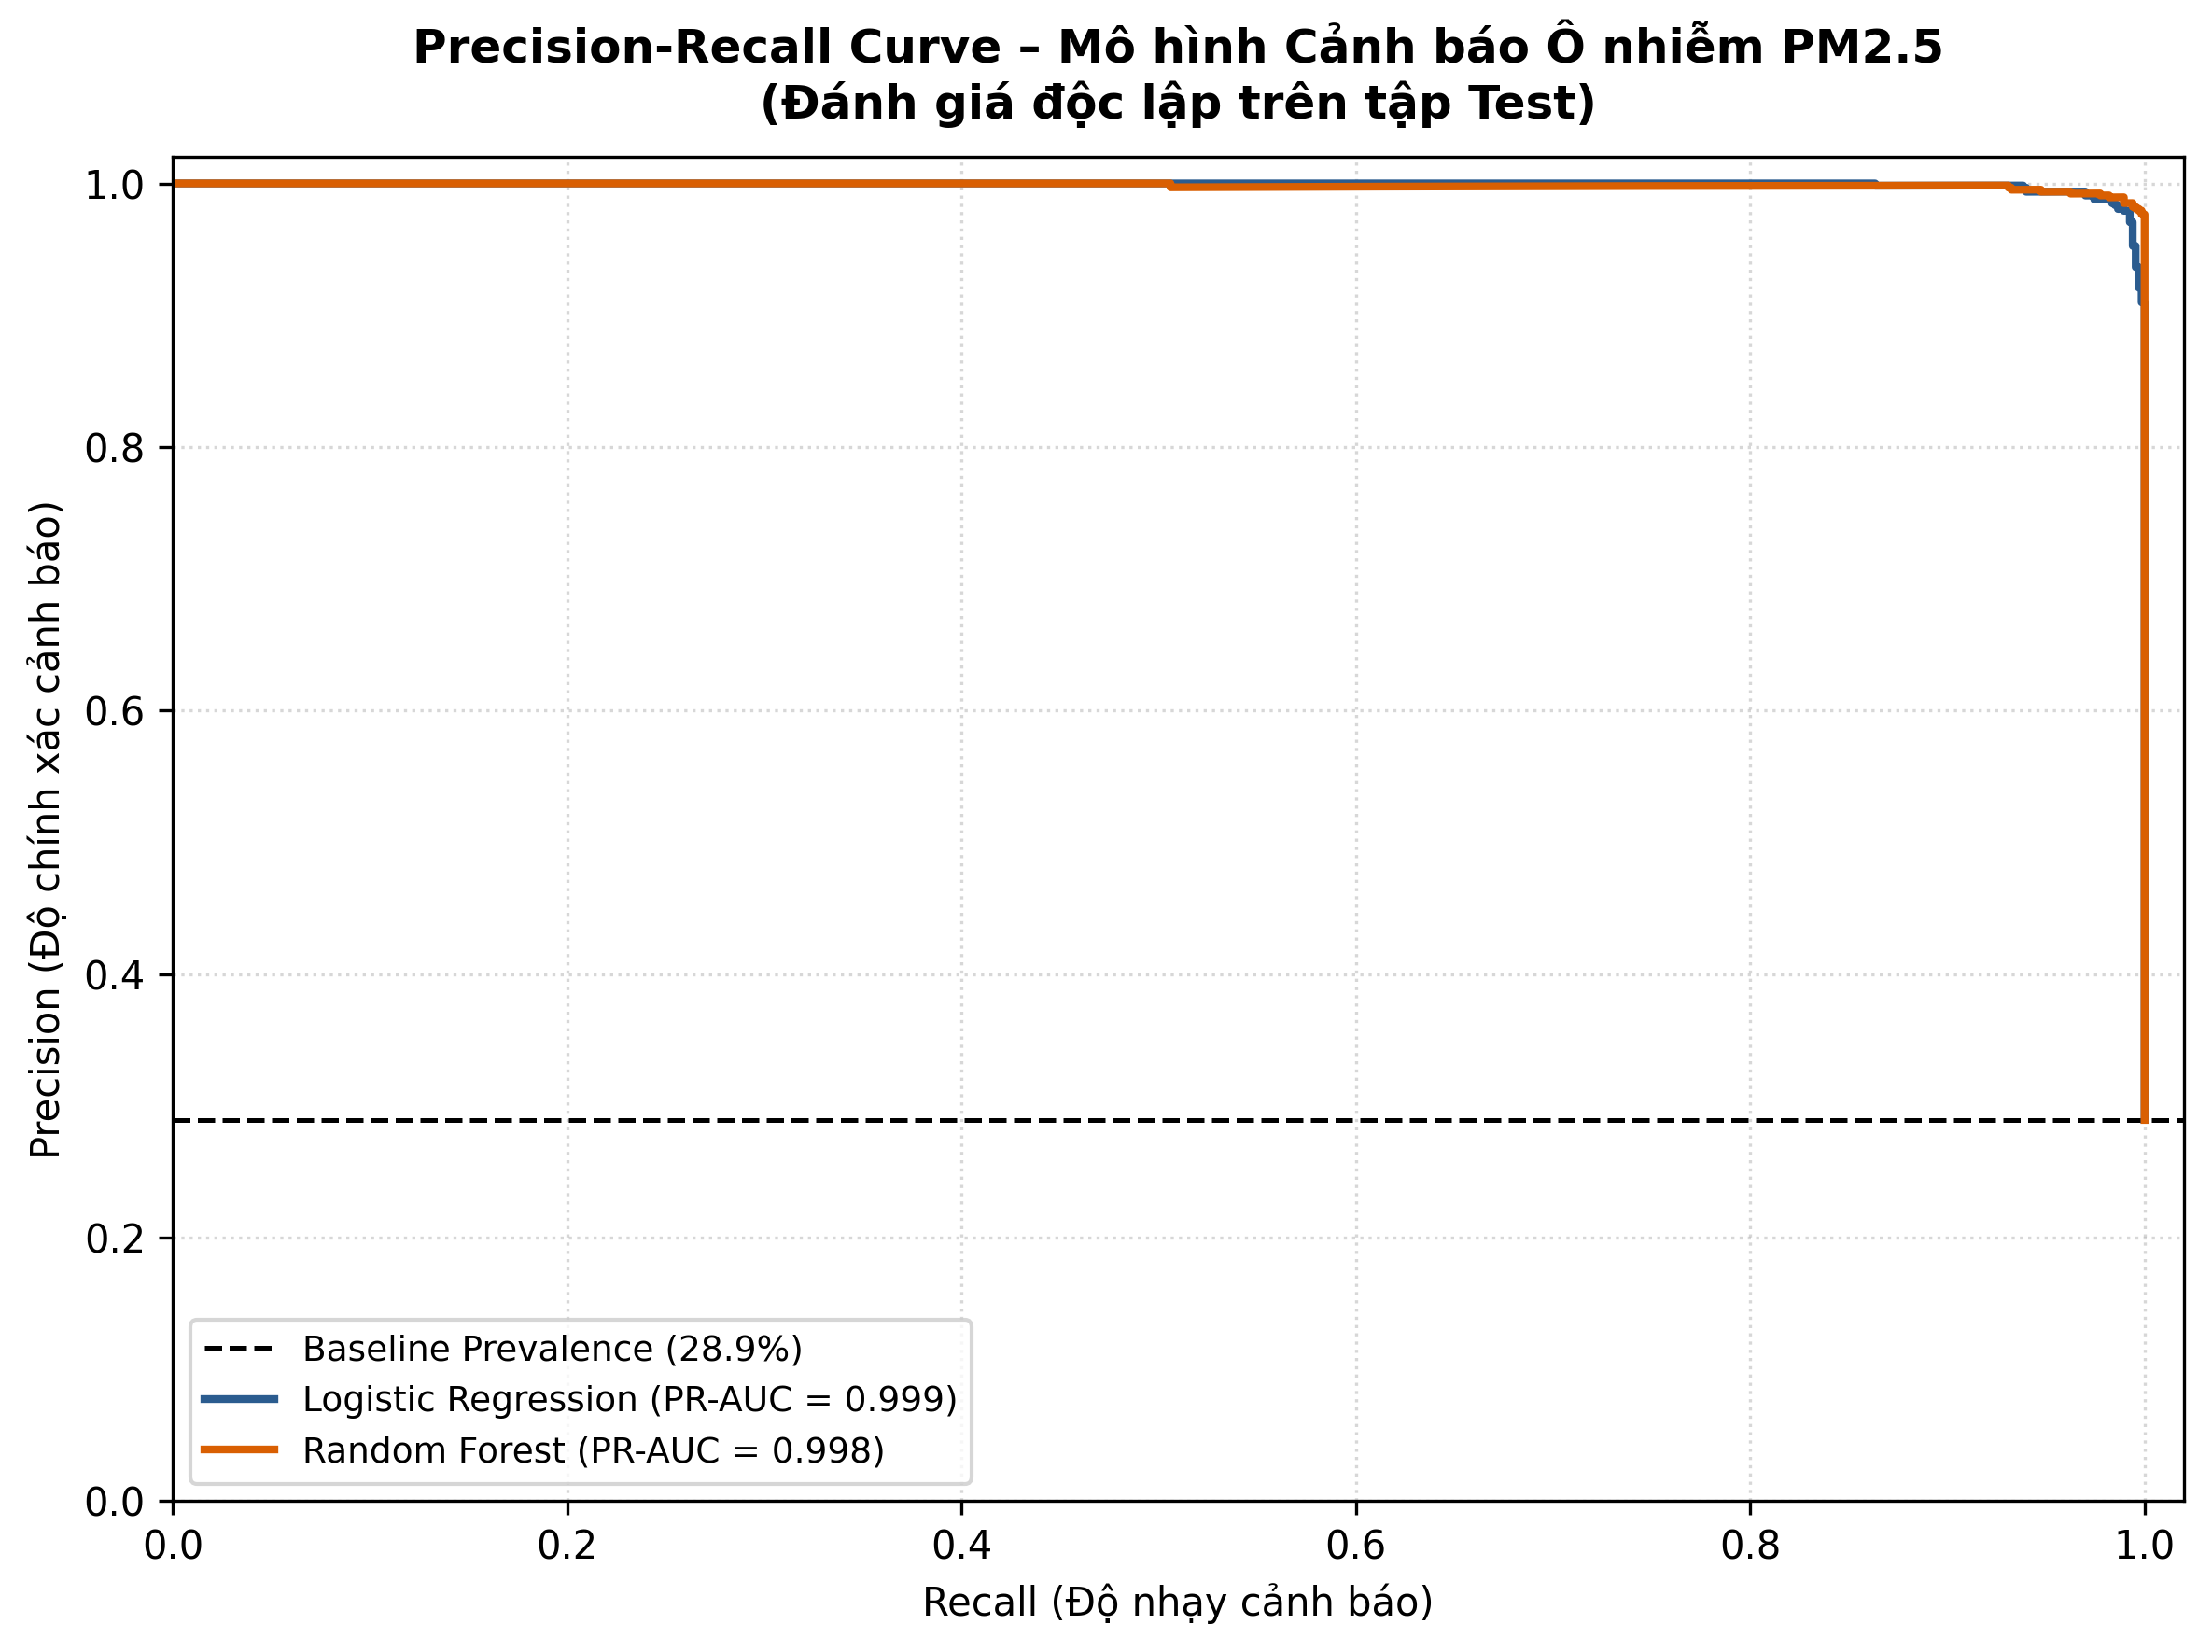

In [7]:
models_dict = {
    "Logistic Regression": logreg,
    "Random Forest": rf,
}
render_pr_curve_figure(models_dict, X_test, y_test, metadata["test_prevalence_valid"], PR_FIG_PATH)
print(f"Đã lưu biểu đồ PR Curve: {PR_FIG_PATH.resolve()}")

from IPython.display import Image
Image(filename=str(PR_FIG_PATH))


## 7. Tầm quan trọng của Đặc trưng (Permutation Importance)

Đo lường mức độ suy giảm Recall khi xáo trộn từng đặc trưng trên tập Test độc lập (thay thế SHAP theo nguyên tắc YAGNI).


BẢNG XẾP HẠNG TẦM QUAN TRỌNG ĐẶC TRƯNG:


,Feature,MDI Importance,Permutation Mean,Permutation Std
0,pm25_rolling_mean_24h,0.576307,6.974474e-01,0.018600
1,pm25_rolling_std_24h,0.069686,3.903904e-03,0.001531
2,relative_humidity,0.008625,1.351351e-03,0.000450
3,temperature,0.021048,7.507508e-04,0.000751
4,pm25_lag24,0.085530,6.006006e-04,0.001531
5,precipitation,0.004012,3.003003e-04,0.000601
6,month_sin,0.024796,0.000000e+00,0.000000
7,is_calm_wind,0.000199,0.000000e+00,0.000000
8,hour_sin,0.003399,-2.220446e-17,0.000950
9,surface_pressure,0.052491,-1.501502e-04,0.001247


Đã lưu biểu đồ Feature Importance: C:\Users\Huy Nguyen\orca\workspaces\air-pollution-analysis\M4-progress\figures\feature_importance.png


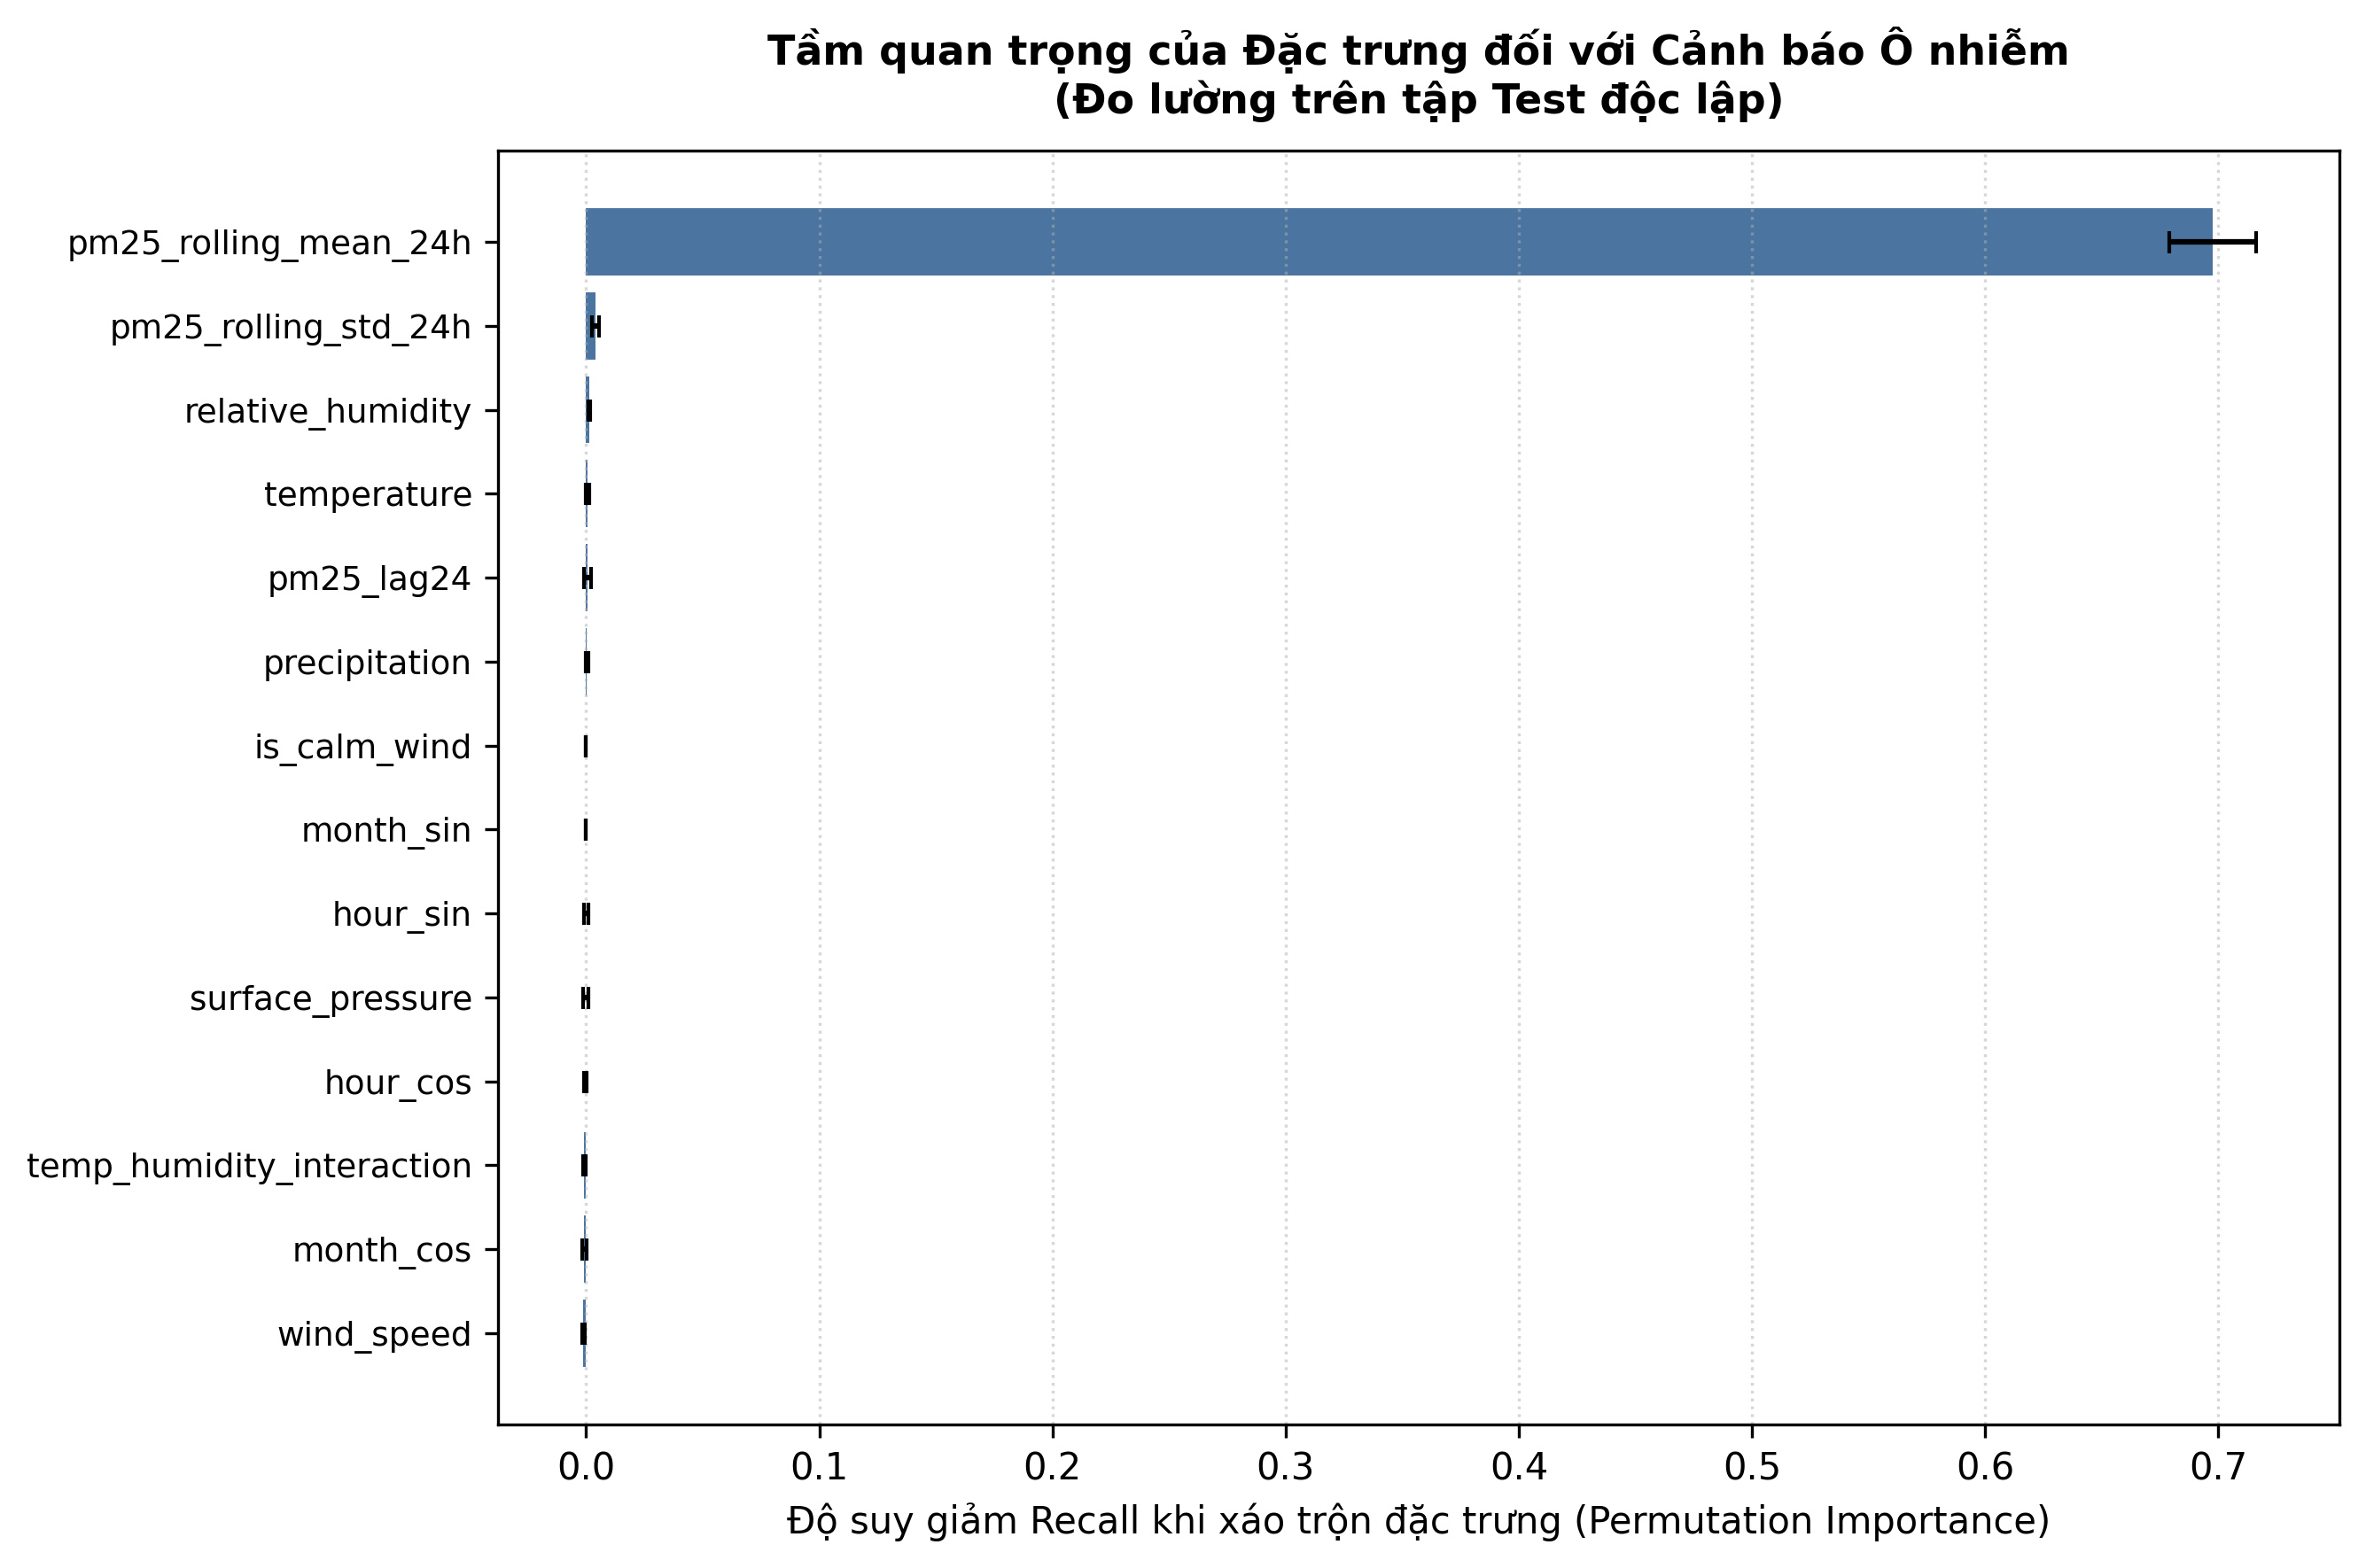

In [8]:
imp_df = compute_feature_importances(rf, X_test, y_test)
print("BẢNG XẾP HẠNG TẦM QUAN TRỌNG ĐẶC TRƯNG:")
display(imp_df)

render_feature_importance_figure(imp_df, FEAT_FIG_PATH)
print(f"Đã lưu biểu đồ Feature Importance: {FEAT_FIG_PATH.resolve()}")
Image(filename=str(FEAT_FIG_PATH))


## 8. Biên bản Kiểm toán 4 Dạng Rò rỉ Dữ liệu & Lý do Loại trừ SMOTE


In [9]:
audit_md = generate_leakage_audit_markdown(metadata, metrics_table)
AUDIT_REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
AUDIT_REPORT_PATH.write_text(audit_md, encoding="utf-8")
print(f"Đã xuất biên bản kiểm toán rò rỉ dữ liệu: {AUDIT_REPORT_PATH.resolve()}")

from IPython.display import Markdown
Markdown(audit_md)


Đã xuất biên bản kiểm toán rò rỉ dữ liệu: C:\Users\Huy Nguyen\orca\workspaces\air-pollution-analysis\M4-progress\reports\classification_leakage_audit.md


# Biên Bản Kiểm Toán Rò Rỉ Dữ Liệu Phân Loại (Data Leakage Audit) — Issue #13

> **Căn cứ học thuật:** Slide W11 & Quy định liêm chính học thuật INFO3020.
> **Ngày thực hiện:** 2026-11-11
> **Tập dữ liệu:** `data/processed/air_pollution_final.parquet`

---

## 1. Kiểm toán 4 Dạng Rò rỉ Dữ liệu Cốt lõi

| Dạng Rò Rỉ | Rủi ro Tiềm ẩn | Biện pháp Phòng ngừa & Bằng chứng Thực nghiệm | Kết luận |
|---|---|---|:---:|
| **1. Target Leakage (Rò rỉ Mục tiêu)** | Sử dụng biến phái sinh trực tiếp từ mục tiêu làm đặc trưng dự báo (ví dụ `pm25_was_missing`). | Cờ `pm25_was_missing` bị loại bỏ hoàn toàn khỏi tập đặc trưng. Các biến trượt (`pm25_rolling_mean_24h`, `pm25_rolling_std_24h`) bắt buộc áp dụng `shift(1)` — chỉ sử dụng dữ liệu từ $t-1$ trở về trước, không chứa giá trị tại thời điểm $t$. | **PASS** |
| **2. Train-Test Contamination (Nhiễm chéo Train-Test)** | Tham số tiền xử lý hoặc ngưỡng quyết định học từ tập Test. | Bộ chuẩn hóa `RobustScaler` và `train_medians` được học duy nhất trên Train partition. Ngưỡng phân loại vận hành ($\tau$) được tối ưu hoàn toàn qua `TimeSeriesSplit(n_splits=5)` trên tập Train; tập Test bị đóng băng hoàn toàn. | **PASS** |
| **3. Temporal Leakage (Rò rỉ Thứ tự Thời gian)** | Sử dụng thông tin tương lai để dự báo quá khứ (random split). | Áp dụng điểm cắt tuyến tính cố định `split_timestamp = 2026-01-15 00:00:00+07:00`. Tuyệt đối không dùng `train_test_split` ngẫu nhiên. Cửa sổ trượt 24h ở đầu tập Test chỉ truy xuất quá khứ ở cuối tập Train. | **PASS** |
| **4. Group / Station Leakage (Rò rỉ Cụm trạm)** | Gộp các trạm khác nhau mà không phân tách thực thể quan trắc. | Dữ liệu baseline thuộc trạm đơn nhất `VN001_HANOI_556_NGUYEN_VAN_CU`, khóa quan trắc được bảo toàn. | **PASS** |

---

## 2. Giải trình Loại trừ Kỹ thuật Tổng hợp Mẫu SMOTE

- **Nguyên nhân loại trừ:** SMOTE (*Synthetic Minority Over-sampling Technique*) tạo ra các điểm dữ liệu nhân tạo bằng phép nội suy tuyến tính lân cận giữa các mẫu thiểu số trong không gian đặc trưng.
- **Hệ quả tiêu cực trên chuỗi thời gian:** Việc tạo điểm nhân tạo làm phá vỡ tính liên tục tự nhiên của chuỗi thời gian khí tượng, tạo ra các bước nhảy vật lý vô lý (ví dụ: nhiệt độ, độ ẩm nhảy vọt giữa các giờ liên tiếp) và làm rò rỉ ranh giới thời gian giữa các pha ô nhiễm.
- **Giải pháp thay thế chuẩn mực:** Sử dụng trọng số lớp nghịch đảo `class_weight='balanced'` trong Logistic Regression và Random Forest, kết hợp tinh chỉnh ngưỡng quyết định vận hành ($\tau$) theo hàm mục tiêu $F_2$ score.

---

## 3. Heuristic Cảnh báo Rò rỉ Dữ liệu & Hiện tượng Chồng lấn Cửa sổ (Window Overlap)
- **Tiêu chí an toàn (Slide W11 Takeaway #4):** *"Nghi ngờ ngay lập tức nếu mô hình đạt điểm Recall hoặc PR-AUC > 99%"*.
- **Kết quả thực nghiệm trên tập Test:**
  - Logistic Regression: Recall = 99.55%, PR-AUC = 0.9989
  - Random Forest: Recall = 100.00%, PR-AUC = 0.9985
- **Phân tích cơ chế toán học vượt ngưỡng > 99%:**
  - Điểm PR-AUC và Recall đạt xấp xỉ hoặc vượt 99% không xuất phát từ việc vi phạm rò rỉ dữ liệu tương lai (toàn bộ đặc trưng đều tuân thủ `shift(1)` triệt để).
  - Nguyên nhân cốt lõi là **hiện tượng chồng lấn cửa sổ trượt (Rolling Window Overlap)**: Đặc trưng `pm25_rolling_mean_24h` tại thời điểm $t$ lấy trung bình từ $t-24$ đến $t-1$, trong khi nhãn mục tiêu $y_t$ lấy trung bình từ $t-23$ đến $t$. Như vậy, đặc trưng quá khứ chia sẻ tới **23/24 (95,8%)** số hạng với nhãn mục tiêu. Kết hợp với tính tự tương quan thời gian rất cao của PM2.5 ($\rho_1 \approx 0,73$), mô hình dễ dàng đạt độ chuẩn xác cực đại ở bài toán cảnh báo nowcasting (1 giờ tới).
  - **Khuyến nghị vận hành & Giới hạn nghiên cứu:** Để cảnh báo mang tính phòng ngừa xa hơn (lead time 24h), hệ thống cần dịch chuyển cửa sổ đặc trưng về $t-24$ trở về trước hoặc dựa chủ yếu vào thông số khí tượng. Ở phạm vi bài toán hiện tại, mô hình phục vụ tốt vai trò cảnh báo tức thời theo thời gian thực.


## 9. Báo Cáo Kết Quả Toàn Diện & Tổng Hợp Phát Hiện Khoa Học

Xuất các báo cáo kết quả nghiệm thu:
1. `reports/classification_results.md`: Tổng hợp bảng hiệu năng, phân tích ngưỡng, bẫy Accuracy, hai quần thể nhãn.
2. `docs/classification_findings.md`: Tài liệu phát hiện khoa học, động lực khí tượng, tương tác nhiệt-ẩm, và đánh đổi Precision-Recall.


In [10]:
results_obj = ClassificationResults(
    split_timestamp=DEFAULT_SPLIT_TIMESTAMP,
    n_train_total=metadata["n_train_total"],
    n_train_valid=metadata["n_train_valid"],
    n_test_total=metadata["n_test_total"],
    n_test_valid=metadata["n_test_valid"],
    train_prevalence_valid=metadata["train_prevalence_valid"],
    test_prevalence_valid=metadata["test_prevalence_valid"],
    train_prevalence_all=metadata["train_prevalence_all"],
    test_prevalence_all=metadata["test_prevalence_all"],
    features=list(X_train.columns),
    best_threshold_logreg=tau_logreg,
    best_threshold_rf=tau_rf,
    metrics_table=metrics_table,
    model_metrics={"dummy": m_dummy, "logreg": m_logreg, "rf": m_rf},
    feature_importances=imp_df,
    leakage_audit_markdown=audit_md,
)

write_classification_report(results_obj, RESULTS_REPORT_PATH)
write_classification_findings(results_obj, FINDINGS_DOC_PATH)

print(f"Đã xuất báo cáo kết quả: {RESULTS_REPORT_PATH.resolve()}")
print(f"Đã xuất tài liệu phát hiện khoa học: {FINDINGS_DOC_PATH.resolve()}")


Đã xuất báo cáo kết quả: C:\Users\Huy Nguyen\orca\workspaces\air-pollution-analysis\M4-progress\reports\classification_results.md
Đã xuất tài liệu phát hiện khoa học: C:\Users\Huy Nguyen\orca\workspaces\air-pollution-analysis\M4-progress\docs\classification_findings.md
